# 04 · Densidad de cotización

Estimación, calibración y validación de `pension_mc.contributions`. El modelo es una cadena de Markov mensual (cotiza / no cotiza) con heterogeneidad permanente:

$$\pi_i(a) = \text{logística}(c_k(a) + \beta\,\eta_i), \quad \eta_i \sim N(0,1), \qquad P(\text{entrar}) = \mu(a)\,\pi_i(a), \quad P(\text{salir}) = \mu(a)\,(1-\pi_i(a))$$

$$\mu(a) = \mu_0\, e^{-\kappa (a - 40)/10}$$

- $\pi_k(a)$: proporción de la población del tipo $k$ (educación × sexo) que cotiza a la edad $a$ (GEIH 2023–2025).
- $\mu(a)$: rotación de corto plazo, que puede caer con la edad ($\kappa > 0$).
- $\beta$: heterogeneidad de largo plazo; con β grande, unos cotizan casi siempre y otros casi nunca.

La GEIH es de corte transversal: no sigue a las personas y no identifica $(\mu_0, \kappa, \beta)$. **Este notebook muestra por qué la calibración importa tanto como las tasas.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from pension_mc import contributions as C
from pension_mc.wages import EDUCACION, NIVELES, SEXOS, clave
from pension_mc.config import DATA_PROCESSED as P

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "legend.frameon": False,
    "lines.linewidth": 2, "figure.figsize": (9, 4.2), "figure.dpi": 110, "font.size": 10,
})
pct = lambda d=0: mtick.PercentFormatter(1, decimals=d)
SEM_MES = 30 / 7
# Semanas exigidas a las cohortes jóvenes (se pensionan después de 2036):
# hombres 1.150 (garantía de pensión mínima, AFP) y 1.300 (Colpensiones); mujeres 1.000 en ambos.
REQ_GPM = {"Hombre": 1150, "Mujer": 1000}
REQ_RPM = {"Hombre": 1300, "Mujer": 1000}
EDAD_PEN = {"Hombre": 62, "Mujer": 57}

geih = pd.read_parquet(P / "geih_pensiones.parquet")
obs = C.tasas_observadas(geih)
tasas = C.suavizar(obs)
pob = C.poblacion_por_tipo(obs)
obj = {g: C.objetivo_periodo(geih, edades=g) for g in C.GRUPOS_PERIODO}
print(f"Celdas tipo × edad: {len(obs)}")
print("Cotizantes con ≥ 3 años en el empleo actual (GEIH):", {f"{a}–{b}": f"{v:.1%}" for (a, b), v in obj.items()})

Celdas tipo × edad: 448
Cotizantes con ≥ 3 años en el empleo actual (GEIH): {'25–44': '46.3%', '45–64': '72.6%'}


## 1. Tasas de cotización por edad (GEIH 2023–2025)

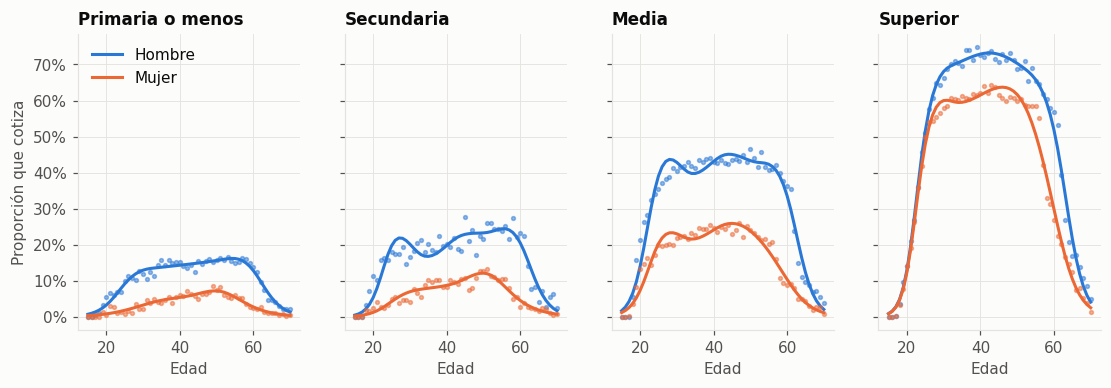

In [2]:
edades = np.arange(C.EDAD_INICIO, C.EDAD_FIN + 1)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True)
for ax, e in zip(axes, NIVELES):
    for i, s in enumerate(SEXOS):
        o = obs[(obs.educ == e) & (obs.sexo == s)]
        ax.plot(o.edad, o.tasa, "o", ms=2.5, color=SERIES[i], alpha=0.5)
        ax.plot(edades, tasas[clave(e, s)], color=SERIES[i], label=s)
    ax.set_title(e, fontsize=11)
    ax.set_xlabel("Edad")
axes[0].yaxis.set_major_formatter(pct())
axes[0].set_ylabel("Proporción que cotiza")
axes[0].legend(loc="upper left")
plt.show()

Puntos: tasa observada por edad. Líneas: logit con spline natural (7 grados de libertad) por tipo. La brecha por educación es enorme: con educación superior cotiza hasta el ~70 % de la población; con primaria o menos, menos del 20 %.

## 2. Calibración: dos formas de leer los datos

Momentos disponibles:

| Momento | Valor | Fuente |
|---|---|---|
| Cotizantes del mes / activos (cotizaron en los últimos 6 meses) | 0,82 | MinTrabajo (datos.gov.co `sk9s-yxmi`), corrigiendo columnas invertidas en las AFP |
| Afiliados (alguna vez cotizaron) / población de 18 a 70 años | 0,77 | MinTrabajo y GEIH; incluye registros inactivos |
| Cotizantes con ≥ 3 años en el empleo actual: 25–44 años / 45–64 años | 0,46 / 0,73 | GEIH (P6426); cota inferior de la duración del periodo de cotización |

Se comparan dos calibraciones:

- **A:** rotación + alguna vez cotizó, con μ constante (κ = 0).
- **B (base):** rotación + duración de los periodos en los dos grupos de edad, con μ que cae con la edad.

"Alguna vez cotizó" no entra en B: el registro de afiliados incluye inactivos fallecidos o fuera del país, y el momento depende de episodios de un mes que casi no pesan en las semanas.

In [3]:
E = list(range(C.EDAD_INICIO, C.EDAD_FIN + 1))
tasas_l = {k: list(v) for k, v in tasas.items()}
# Calibración A: rotación + alguna vez (búsqueda directa sobre (μ, β))
from scipy import optimize
def resid_A(p):
    m = C.ModeloCotizacion(E, tasas_l, np.exp(p[0]), np.exp(p[1]))
    mo = C.momentos(m, pob)
    return [mo["cotizantes_sobre_activos"] - 0.82, mo["alguna_vez"] - 0.77]
rA = optimize.least_squares(resid_A, x0=np.log([0.1, 1.3]), diff_step=0.05)
mA = C.ModeloCotizacion(E, tasas_l, float(np.exp(rA.x[0])), float(np.exp(rA.x[1])))
mA.calibracion = C.momentos(mA, pob)
mB = C.ModeloCotizacion.cargar()          # calibración base, estimada con C.estimar()
cal = pd.DataFrame({
    "A: rotación + alguna vez": {"μ₀": mA.mu, "κ": mA.kappa, "β": mA.beta, **mA.calibracion},
    "B: rotación + duración (base)": {"μ₀": mB.mu, "κ": mB.kappa, "β": mB.beta, **{k: mB.calibracion[k] for k in mA.calibracion}},
    "Dato": {"cotizantes_sobre_activos": 0.82, "alguna_vez": 0.77, "periodo_25_44": obj[(25, 44)], "periodo_45_64": obj[(45, 64)]},
}).T[["μ₀", "κ", "β", "tasa", "cotizantes_sobre_activos", "alguna_vez", "periodo_25_44", "periodo_45_64"]]
cal.style.format("{:.3f}", na_rep="")

,μ₀,κ,β,tasa,cotizantes_sobre_activos,alguna_vez,periodo_25_44,periodo_45_64
A: rotación + alguna vez,0.120,0.000,1.441,0.289,0.820,0.770,0.311,0.308
B: rotación + duración (base),0.194,0.828,4.091,0.288,0.820,0.614,0.463,0.726
Dato,,,,,0.820,0.770,0.463,0.726


- **A** reproduce "alguna vez cotizó", pero muy pocos de sus cotizantes llevan 3 años o más cotizando sin pausa, cuando en la GEIH la mayoría lleva 3 años o más **en el mismo empleo** (y un periodo de cotización dura al menos eso). A genera demasiada rotación para el núcleo de trabajadores formales.
- **B** reproduce la rotación y la duración en ambos grupos de edad: unos cotizan casi siempre y una franja, sobre todo joven, entra y sale. La rotación mensual cae de ~0,7 a los 25 años a ~0,05 a los 55. A cambio, el 61 % de la población habría cotizado alguna vez, frente al 77 % de afiliados registrados. La diferencia es plausible: el registro incluye afiliados fallecidos o fuera del país, y el modelo no capta bien los episodios aislados de un mes.

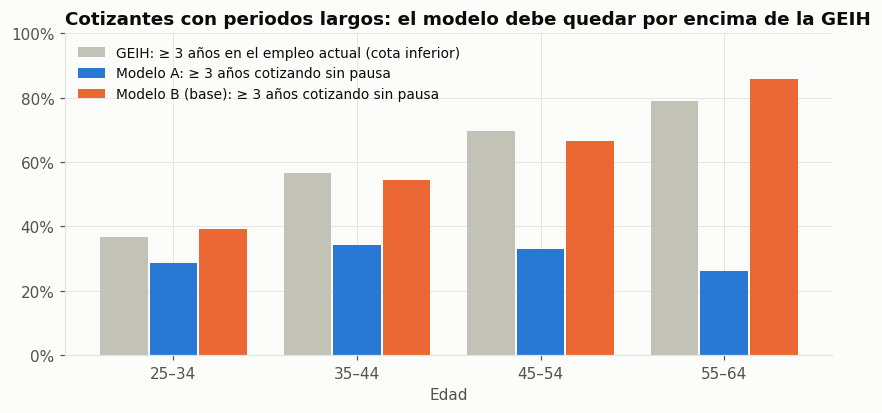

In [4]:
# Validación con la antigüedad por edad: el periodo de cotización simulado debe ser >= la antigüedad observada
c = geih[(geih.cotiza == 1) & geih.anio.isin(C.ANIOS_TASAS) & geih.edad.between(25, 64)].copy()
grupos = [(25, 34), (35, 44), (45, 54), (55, 64)]
etiq = [f"{a}–{b}" for a, b in grupos]
obs_g = [np.average(c[c.edad.between(a, b)].antiguedad_empleo >= 36, weights=c[c.edad.between(a, b)].fex) for a, b in grupos]
sim = {}
for nombre, m in [("A", mA), ("B (base)", mB)]:
    mo = C.momentos(m, pob, n_por_tipo=2_000, grupos_periodo=grupos)
    sim[nombre] = [mo[f"periodo_{a}_{b}"] for a, b in grupos]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(grupos))
ax.bar(x - 0.27, obs_g, 0.26, color="#c3c2b7", label="GEIH: ≥ 3 años en el empleo actual (cota inferior)")
for i, (nombre, v) in enumerate(sim.items()):
    ax.bar(x + 0.27 * i, v, 0.26, color=SERIES[i], label=f"Modelo {nombre}: ≥ 3 años cotizando sin pausa")
ax.set_xticks(x, etiq)
ax.set_xlabel("Edad")
ax.yaxis.set_major_formatter(pct())
ax.set_ylim(0, 1)
ax.set_title("Cotizantes con periodos largos: el modelo debe quedar por encima de la GEIH")
ax.legend(loc="upper left", fontsize=9)
plt.show()

La calibración B se ajusta con los grupos 25–44 y 45–64, y queda cerca de la cota también en los cuatro grupos decenales. La versión anterior del modelo, con μ constante, quedaba por debajo de la cota desde los 45 años: la estabilidad laboral crece con la edad y eso pesa justo en los años que definen la pensión. La calibración A queda muy por debajo en todos los grupos.

## 3. Validación: tasa de cotización simulada vs. observada (calibración B)

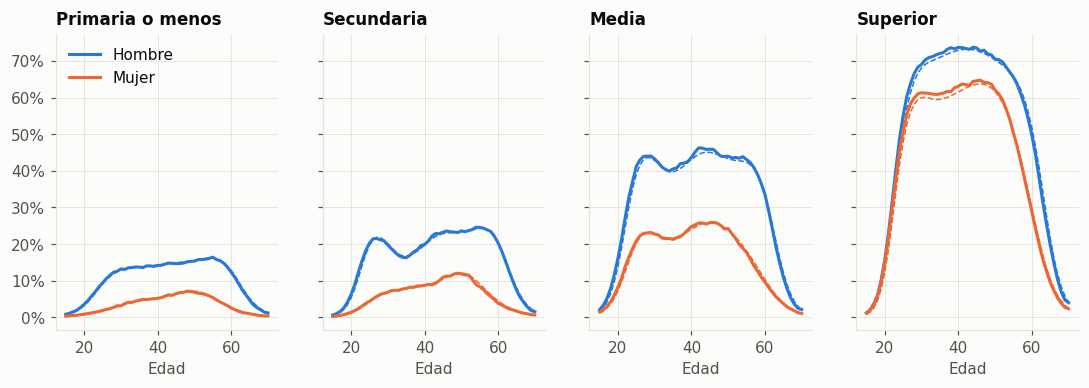

,error_abs_max_20_60
tipo,
Primaria o menos | Hombre,0.5%
Primaria o menos | Mujer,0.5%
Secundaria | Hombre,1.6%
Secundaria | Mujer,1.1%
Media | Hombre,2.8%
Media | Mujer,1.5%
Superior | Hombre,4.2%
Superior | Mujer,3.8%


In [5]:
filas = []
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5), sharey=True)
for ax, e in zip(axes, NIVELES):
    for i, s in enumerate(SEXOS):
        x_ = mB.simular(C.EDAD_INICIO, s, e, len(E) * 12, 4_000, seed=11)
        anual = x_.reshape(4_000, len(E), 12).mean(axis=(0, 2))
        ax.plot(E, tasas[clave(e, s)], color=SERIES[i], lw=1, ls="--")
        ax.plot(E, anual, color=SERIES[i], label=s)
        sel = (np.array(E) >= 20) & (np.array(E) <= 60)
        filas.append({"tipo": f"{e} | {s}", "error_abs_max_20_60": np.max(np.abs(anual - tasas[clave(e, s)])[sel])})
    ax.set_title(e, fontsize=11)
    ax.set_xlabel("Edad")
axes[0].yaxis.set_major_formatter(pct())
axes[0].legend(loc="upper left")
plt.show()
pd.DataFrame(filas).set_index("tipo").style.format("{:.1%}")

Líneas continuas: tasa simulada. Líneas discontinuas: tasa objetivo de la GEIH. La cadena sigue el perfil por edad con errores pequeños; donde la tasa cambia rápido (entrada al mercado laboral), la cadena va con un leve rezago.

## 4. ¿Cuánto cotiza cada persona? Densidad individual entre los 20 años y la edad de pensión

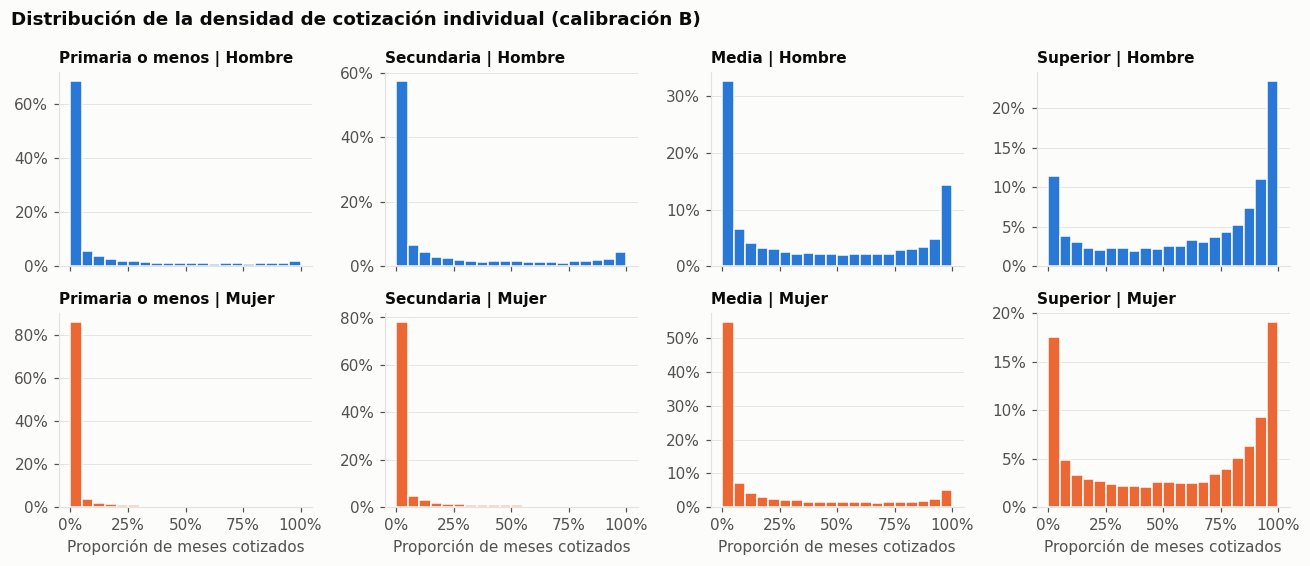

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.2), sharex=True)
dens = {}
for j, e in enumerate(NIVELES):
    for i, s in enumerate(SEXOS):
        x_ = mB.simular(20, s, e, (EDAD_PEN[s] - 20) * 12, 10_000, seed=21)
        d = x_.mean(axis=1)
        dens[(e, s)] = d
        ax = axes[i, j]
        ax.hist(d, bins=np.linspace(0, 1, 21), color=SERIES[i], edgecolor=SURFACE, linewidth=1,
                weights=np.full(len(d), 1 / len(d)))
        ax.yaxis.set_major_formatter(pct())
        ax.set_title(f"{e} | {s}", fontsize=10)
        ax.grid(axis="x", visible=False)
for ax in axes[1]:
    ax.xaxis.set_major_formatter(pct())
    ax.set_xlabel("Proporción de meses cotizados")
fig.suptitle("Distribución de la densidad de cotización individual (calibración B)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

La distribución es **bimodal**: la mayoría de las personas cotiza casi siempre o casi nunca. El tipo (educación y sexo) cambia sobre todo *cuántas* personas están en cada extremo. Este patrón es el que identifica la antigüedad de la GEIH; con la calibración A la distribución sería unimodal y concentrada alrededor del promedio del tipo.

## 5. Semanas acumuladas a la edad de pensión

In [7]:
filas = []
for e, s in C.tipos():
    w = C.semanas(mB.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, 20_000, seed=1))[:, -1]
    wa = C.semanas(mA.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, 20_000, seed=1))[:, -1]
    filas.append({"educación": e, "sexo": s, "P25": np.percentile(w, 25), "mediana": np.median(w), "P75": np.percentile(w, 75),
                  "≥ req. AFP (GPM)": np.mean(w >= REQ_GPM[s]), "≥ req. Colpensiones": np.mean(w >= REQ_RPM[s]),
                  "≥ req. AFP con calibración A": np.mean(wa >= REQ_GPM[s])})
semanas_tipo = pd.DataFrame(filas).set_index(["educación", "sexo"])
semanas_tipo.style.format({"P25": "{:,.0f}", "mediana": "{:,.0f}", "P75": "{:,.0f}", "≥ req. AFP (GPM)": "{:.1%}",
                           "≥ req. Colpensiones": "{:.1%}", "≥ req. AFP con calibración A": "{:.1%}"})

Requisitos para las cohortes que se pensionen después de 2036: hombres, 1.150 semanas para la garantía de pensión mínima en las AFP y 1.300 en Colpensiones; mujeres, 1.000 en ambos (reducción gradual ordenada por las sentencias C-197 de 2023 y C-054 de 2024).

## 6. Sensibilidad del resultado a la calibración

In [8]:
g25 = geih[(geih.anio == 2025)].copy()
g25["educ"] = g25.nivel_educativo.astype(str).map(EDUCACION)
g25["sexo"] = g25.sexo.astype(str)

def composicion(a, b):
    d = g25[g25.edad.between(a, b)]
    w = d.groupby(["educ", "sexo"]).fex.sum()
    return w / w.sum()

def alcanza(m, n=10_000):
    return {(e, s): np.mean(C.semanas(m.simular(15, s, e, (EDAD_PEN[s] - 15) * 12, n, seed=1))[:, -1] >= REQ_GPM[s])
            for e, s in C.tipos()}

jov, may = composicion(25, 35), composicion(60, 70)
casos = {"A: rotación + alguna vez (κ = 0)": mA, "B: rotación + duración por edad (base)": mB}
for nombre, kw in [("B1: rotación 0,79", dict(objetivo_ratio=0.79, objetivos_periodo=obj)),
                   ("B2: rotación 0,88", dict(objetivo_ratio=0.88, objetivos_periodo=obj)),
                   ("B3: duración +5 puntos (cambios de empleo sin dejar de cotizar)",
                    dict(objetivos_periodo={g: v + 0.05 for g, v in obj.items()})),
                   ("B4: μ constante, duración 35–54", dict(objetivos_periodo={(35, 54): C.objetivo_periodo(geih)}))]:
    casos[nombre] = C.calibrar(tasas, pob, **kw)
filas = []
for nombre, m in casos.items():
    r = alcanza(m)
    filas.append({"calibración": nombre, "μ₀": m.mu, "κ": m.kappa, "β": m.beta,
                  "composición de 25–35 años": sum(jov[k] * r[k] for k in r),
                  "composición de 60–70 años": sum(may[k] * r[k] for k in r)})
sens = pd.DataFrame(filas).set_index("calibración")
sens.style.format({"μ₀": "{:.3f}", "κ": "{:.2f}", "β": "{:.2f}", "composición de 25–35 años": "{:.1%}", "composición de 60–70 años": "{:.1%}"}).set_caption(
    "Proporción que alcanza las semanas de la garantía de pensión mínima")

,μ₀,κ,β,composición de 25–35 años,composición de 60–70 años
calibración,,,,,
A: rotación + alguna vez (κ = 0),0.120,0.00,1.44,34.0%,16.4%
B: rotación + duración por edad (base),0.194,0.83,4.09,37.6%,20.6%
"B1: rotación 0,79",0.942,1.77,5.63,38.2%,21.3%
"B2: rotación 0,88",0.074,0.55,2.27,36.0%,18.7%
B3: duración +5 puntos (cambios de empleo sin dejar de cotizar),0.472,1.35,6.16,38.5%,21.5%
"B4: μ constante, duración 35–54",0.611,0.00,7.40,38.9%,21.8%


- Dentro de la familia B, el resultado casi no depende de la rotación, del umbral de duración ni de que la rotación caiga con la edad: los parámetros cambian mucho (μ₀ entre 0,07 y 0,94, β entre 2,3 y 7,4), pero la proporción que alcanza las semanas se mueve entre 36,0 % y 38,9 %. Lo que importa es la **heterogeneidad de largo plazo**, y la antigüedad observada la ancla.
- La calibración A, que ignora la antigüedad, da ~4 puntos menos (34 % vs. 38 %).
- **Contraste externo, en orden de magnitud:** las cifras públicas de cobertura van del 18 % de los trabajadores que se pensionan (DANE, citado por la prensa) al 24–30 % de los adultos mayores con pensión. Estas últimas incluyen pensiones de sobrevivientes, regímenes especiales y reglas antiguas con menos semanas. Con la composición educativa de quienes hoy tienen 60–70 años, el modelo da 21 %.

## 7. Condicionar en la historia de la persona

Para el simulador, la persona dice cuántas semanas ya cotizó. Eso informa su η: alguien de 40 años con 900 semanas probablemente está en el grupo que cotiza casi siempre.

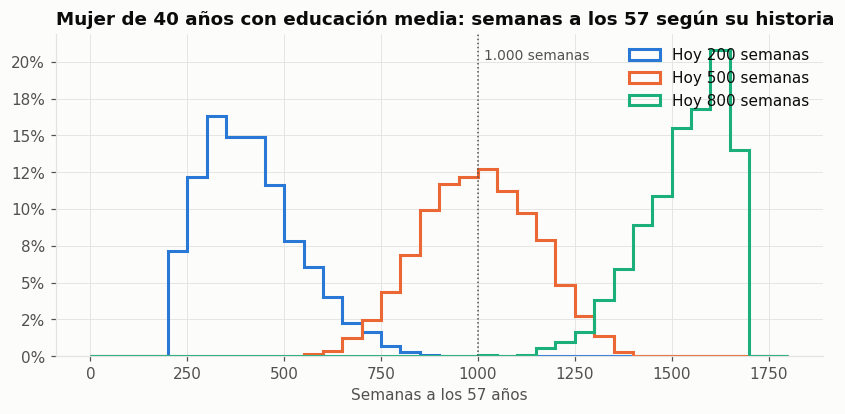

,η medio,cotiza hoy,mediana a los 57,P(≥ 1.000)
semanas a los 40,,,,
200,0.51,29%,397,0%
500,0.88,62%,"1,001",51%
800,1.23,87%,"1,559",100%


In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
filas = []
for i, sem in enumerate([200, 500, 800]):
    eta, est = mB.condicionar(40, "Mujer", "Media", sem, 4_000, seed=31)
    fut = mB.simular(40, "Mujer", "Media", (57 - 40) * 12, 4_000, eta=eta, estado_inicial=est, seed=32)
    total = sem + C.semanas(fut)[:, -1]
    ax.hist(total, bins=np.arange(0, 1801, 50), histtype="step", lw=2, color=SERIES[i],
            weights=np.full(len(total), 1 / len(total)), label=f"Hoy {sem} semanas")
    filas.append({"semanas a los 40": sem, "η medio": eta.mean(), "cotiza hoy": est.mean(),
                  "mediana a los 57": np.median(total), "P(≥ 1.000)": np.mean(total >= 1000)})
ax.axvline(1000, color=INK2, lw=1, ls=":")
ax.annotate("1.000 semanas", (1000, ax.get_ylim()[1] * 0.92), xytext=(4, 0), textcoords="offset points", color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(pct())
ax.set_xlabel("Semanas a los 57 años")
ax.set_title("Mujer de 40 años con educación media: semanas a los 57 según su historia")
ax.legend(loc="upper right")
plt.show()
pd.DataFrame(filas).set_index("semanas a los 40").style.format({"η medio": "{:.2f}", "cotiza hoy": "{:.0%}",
                                                               "mediana a los 57": "{:,.0f}", "P(≥ 1.000)": "{:.0%}"})

## Hallazgos

1. **La densidad de cotización es bimodal.** La mayoría cotiza casi siempre o casi nunca. Lo que separa a los tipos es cuántas personas están en cada extremo, no una densidad "promedio" que todos comparten. Con la tasa promedio, nadie llegaría a las semanas (notebook 01); con la heterogeneidad, una fracción importante sí llega.
2. **La calibración es el supuesto crítico de este componente.** La GEIH no sigue a las personas, así que la persistencia se calibra con datos administrativos (rotación de 6 meses) y con la antigüedad en el empleo de la propia GEIH. Ignorar la antigüedad (calibración A) subestima en ~4 puntos la proporción que alcanza las semanas y, para algunos grupos, la reduce casi a la mitad (mujeres con educación media: 10 % vs. 18 %).
3. **La validación obligó a mejorar el modelo.** Con una rotación constante, los periodos de cotización simulados quedaban por debajo de la antigüedad observada desde los 45 años. Al permitir que la rotación caiga con la edad (de ~0,7 al mes a los 25 años a ~0,05 a los 55), el modelo cumple la cota en todas las edades. El resultado central casi no cambia (38,9 % vs. 37,6 %), pero el modelo queda coherente con los datos.
4. **Brechas enormes por educación y sexo.** Con la calibración base, la proporción que alcanza las semanas de la garantía de pensión mínima va del 3 % (mujeres con primaria o menos) al 65 % (hombres con educación superior). Las mujeres cotizan menos meses, aunque la reducción de semanas a 1.000 compensa parte de la brecha.
5. **La historia de la persona cambia mucho el pronóstico.** A los 40 años, una mujer con educación media y 800 semanas casi seguro llega a 1.000; con 200 semanas, casi seguro no. El simulador condicionará en las semanas cotizadas.
6. **Validación:** la cadena reproduce las tasas por edad de la GEIH (error máximo de ~4 puntos), la rotación administrativa y la duración de los periodos por edad, y da una cobertura del mismo orden que las cifras públicas.

**Limitaciones:**
- Las tasas por edad son de corte transversal (2023–2025): se supone que las cohortes jóvenes cotizarán a cada edad como cotizan hoy los mayores de su mismo tipo, sin tendencia de formalización.
- η no está correlacionado con el salario del paso 4 (en la realidad, quien gana más cotiza más).
- La rotación administrativa tiene definiciones ambiguas: la fila de las AFP del dataset parece tener las columnas invertidas.